# Cafe Sales: Cleaning Dirty Data

**Goal:** Clean the 10,000-row Cafe Sales dataset and extract some basic insights.

**Outputs:** `data/clean_cafe_sales.csv` and `reports/figures`.

### Set-up
* Ensure compatibility with requirements.txt
* Run all cells from the top

In [1]:
RAW_PATH = "data/dirty_cafe_sales.csv"
CLEAN_PATH = "data/clean_cafe_sales.csv"

In [2]:
import duckdb as ddb
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 100)
Path("reports/figures").mkdir(parents=True, exist_ok=True)

# Establish in-memory DuckDB database
con = ddb.connect()

### Clean


Trim strings, standardize type casting, standardize null values

In [3]:
con.execute(f"""
CREATE OR REPLACE VIEW raw_data AS
SELECT *
FROM read_csv_auto('{RAW_PATH}',header=True);
""")

con.execute(f"""
CREATE OR REPLACE TABLE typed AS
SELECT
    "Transaction ID" AS transaction_id,
    CASE
        WHEN "Item" IN ('ERROR','UNKNOWN','None','') THEN NULL
        ELSE TRIM("Item") END AS item,
    CASE
        WHEN "Quantity" IN ('ERROR','UNKNOWN','None','') THEN NULL
        ELSE TRY_CAST("Quantity" AS INT) END AS quantity,
    CASE
        WHEN "Price Per Unit" IN ('ERROR','UNKNOWN','None','') THEN NULL
        ELSE ROUND(TRY_CAST("Price Per Unit" AS DOUBLE),2) END AS price_per_unit,
    CASE
        WHEN "Total Spent" IN ('ERROR','UNKNOWN','None','') THEN NULL
        ELSE ROUND(TRY_CAST("Total Spent" AS DOUBLE),2) END AS total_spent,
    CASE
        WHEN "Payment Method" IN ('ERROR','UNKNOWN','None','') THEN NULL
        ELSE TRIM("Payment Method") END AS payment_method,
    CASE
        WHEN "Location" IN ('ERROR','UNKNOWN','None','') 
            THEN NULL
        ELSE TRIM("Location") END AS location,
    CASE
        WHEN "Transaction Date" IN ('ERROR','UNKNOWN','None','') THEN NULL
        ELSE TRY_CAST("Transaction Date" AS DATE) END AS transaction_date
FROM raw_data;
""")


Fill missing `total_spent` from `quantity` × `price_per_unit`. Before this step, the original totals matched quantity × price on all 8,544 rows where all three values were present, so no existing values were overridden.

In [4]:
con.execute("""
CREATE OR REPLACE TABLE recalc_t AS
SELECT 
    transaction_id, item, quantity, price_per_unit, 
    CASE 
        WHEN quantity IS NOT NULL AND price_per_unit IS NOT NULL THEN ROUND(quantity * price_per_unit, 2)
        ELSE total_spent END AS total_spent,
    payment_method, location, transaction_date
FROM typed
""")

Fill missing `quantity` and `price_per_unit` cells when null and calculation possible, now preferring the original value if present


In [5]:
con.execute("""
CREATE OR REPLACE TABLE recalc_qp AS
SELECT 
    transaction_id, item, 
    CASE
        WHEN quantity IS NULL AND price_per_unit IS NOT NULL AND total_spent IS NOT NULL 
            THEN TRY_CAST(ROUND(total_spent/price_per_unit) AS INT)
        ELSE quantity END AS quantity,
    CASE
        WHEN price_per_unit IS NULL AND quantity IS NOT NULL AND total_spent IS NOT NULL 
            THEN ROUND(total_spent/quantity, 2)
        ELSE price_per_unit END AS price_per_unit,
    total_spent, payment_method, location, transaction_date
FROM recalc_t
""")


Remove duplicate primary keys (retain most recent)

In [6]:
con.execute("""
CREATE OR REPLACE TABLE recalc AS
SELECT 
    *
FROM recalc_qp
QUALIFY ROW_NUMBER() OVER(
    PARTITION BY transaction_id ORDER BY transaction_date DESC
) = 1;
""")

Create `day`, `month`, `year` columns to simplify analysis

In [7]:

con.execute("""
CREATE OR REPLACE TABLE clean_data AS
SELECT
    transaction_id, item, quantity, price_per_unit, total_spent, payment_method, location, transaction_date,
    YEAR(transaction_date) AS transaction_year,
    MONTH(transaction_date) AS transaction_month,
    DAY(transaction_date) AS transaction_day
FROM recalc
""")

### Export
To `data/clean_cafe_sales.csv`.

In [8]:
con.execute(f""" 
COPY (SELECT * FROM clean_data) 
    TO '{CLEAN_PATH}' (HEADER, DELIMITER ','); 
""") 

### Quality checks


Cleaning summary

In [9]:
# Sentinel values converted to true NULL
to_null_count = con.sql("""
SELECT 
    SUM(
        CASE WHEN "Item" IN ('ERROR','UNKNOWN','None','') THEN 1 ELSE 0 END +
        CASE WHEN "Quantity" IN ('ERROR','UNKNOWN','None','') THEN 1 ELSE 0 END +
        CASE WHEN "Price Per Unit" IN ('ERROR','UNKNOWN','None','') THEN 1 ELSE 0 END +
        CASE WHEN "Total Spent" IN ('ERROR','UNKNOWN','None','') THEN 1 ELSE 0 END +
        CASE WHEN "Payment Method" IN ('ERROR','UNKNOWN','None','') THEN 1 ELSE 0 END +
        CASE WHEN "Location" IN ('ERROR','UNKNOWN','None','') THEN 1 ELSE 0 END +
        CASE WHEN "Transaction Date" IN ('ERROR','UNKNOWN','None','') THEN 1 ELSE 0 END    
    ) AS to_null
FROM raw_data
""").df()
display(to_null_count)

# Values recovered
# Computed with Pandas
typed_df = con.sql(f"SELECT * FROM typed").df()
clean_df = con.sql(f"SELECT * FROM clean_data").df().iloc[:, :-3]

nulls_before = typed_df.isna().sum().sum()
nulls_after  = clean_df.isna().sum().sum()

print(f"NULLs before recovery: {nulls_before}")
print(f"NULLs after recovery: {nulls_after}")
print(f"Values recovered: {nulls_before - nulls_after}")

# Computed with DuckDB/SQL
recovered = con.sql("""
WITH before AS (
  SELECT
    SUM(CASE WHEN quantity IS NULL THEN 1 ELSE 0 END) +
    SUM(CASE WHEN price_per_unit IS NULL THEN 1 ELSE 0 END) +
    SUM(CASE WHEN total_spent  IS NULL THEN 1 ELSE 0 END) AS total_nulls
  FROM typed
),
after AS (
  SELECT
    SUM(CASE WHEN quantity IS NULL THEN 1 ELSE 0 END) +
    SUM(CASE WHEN price_per_unit IS NULL THEN 1 ELSE 0 END) +
    SUM(CASE WHEN total_spent  IS NULL THEN 1 ELSE 0 END) AS total_nulls
  FROM clean_data
)
SELECT (before.total_nulls - after.total_nulls) AS recovered_values
FROM before, after;
""").df()
display(recovered)

# Duplicates removed
rows_before = len(typed_df)
rows_after = len(clean_df)
print(f"Duplicates removed: {rows_before - rows_after}")

# Post-cleaning consistency check (0 by construction, since totals were recalculated above)
mismatch_rate = con.sql("""
SELECT AVG(
    CASE 
        WHEN quantity IS NOT NULL AND price_per_unit IS NOT NULL AND total_spent IS NOT NULL
            AND (ROUND(TRY_CAST(quantity * price_per_unit AS DOUBLE), 2) <> total_spent) THEN 1
        ELSE 0 END 
) AS mismatch_rate
FROM clean_data                     
""").df()
display(mismatch_rate)

# Mismatch check on ORIGINAL values (before recalculation)
original_mismatch = con.sql("""
SELECT
  COUNT(*) FILTER (WHERE quantity IS NOT NULL AND price_per_unit IS NOT NULL AND total_spent IS NOT NULL) AS comparable_rows,
  COUNT(*) FILTER (WHERE quantity IS NOT NULL AND price_per_unit IS NOT NULL AND total_spent IS NOT NULL
                   AND ROUND(quantity * price_per_unit, 2) <> total_spent) AS mismatched_rows
FROM typed
""").df()
display(original_mismatch)

# Primary key uniqueness 
duplicate_ids = con.sql("""
SELECT
    COUNT(transaction_id) AS total_keys,
    COUNT(DISTINCT transaction_id) AS distinct_keys
FROM clean_data
""").df()
display(duplicate_ids)

,to_null
0,3256.0


NULLs before recovery: 10082
NULLs after recovery: 8684
Values recovered: 1398


,recovered_values
0,1398.0


Duplicates removed: 0


,mismatch_rate
0,0.0


,comparable_rows,mismatched_rows
0,8544,0


,total_keys,distinct_keys
0,10000,10000


### Missing values: raw vs. clean
Counts of missing cells per column before and after cleaning. "Raw missing" is blank cells plus the placeholder text (`ERROR`, `UNKNOWN`, `None`). The nulls that remain are cells that can't be derived from other columns, so I left them as NULL instead of guessing.

In [10]:
SENTINELS = ["ERROR", "UNKNOWN", "None", ""]

# raw column name -> clean column name
col_map = {
    "Transaction ID": "transaction_id",
    "Item": "item",
    "Quantity": "quantity",
    "Price Per Unit": "price_per_unit",
    "Total Spent": "total_spent",
    "Payment Method": "payment_method",
    "Location": "location",
    "Transaction Date": "transaction_date",
}

raw_profile_df = con.sql("SELECT * FROM raw_data").df()
clean_profile_df = con.sql("SELECT * FROM clean_data").df()

profile = pd.DataFrame({
    "blank_cells": {c: raw_profile_df[r].isna().sum() for r, c in col_map.items()},
    "placeholder_text": {c: raw_profile_df[r].isin(SENTINELS).sum() for r, c in col_map.items()},
    "clean_nulls": {c: clean_profile_df[c].isna().sum() for c in col_map.values()},
})
profile["raw_missing"] = profile["blank_cells"] + profile["placeholder_text"]
profile["recovered"] = profile["raw_missing"] - profile["clean_nulls"]

profile = profile[["raw_missing", "placeholder_text", "recovered", "clean_nulls"]]
profile.loc["TOTAL"] = profile.sum()
display(profile)

,raw_missing,placeholder_text,recovered,clean_nulls
transaction_id,0,0,0,0
item,969,636,0,969
quantity,479,341,441,38
price_per_unit,533,354,495,38
total_spent,502,329,462,40
payment_method,3178,599,0,3178
location,3961,696,0,3961
transaction_date,460,301,0,460
TOTAL,10082,3256,1398,8684


### Light analysis

In [11]:
# Total revenue 
total_revenue = con.sql("""
SELECT 
    SUM(total_spent) AS total_revenue 
FROM clean_data
""").df()
display(total_revenue)

# Revenue by month 
monthly_revenue = con.sql("""
SELECT 
    transaction_month,
    SUM(total_spent) as revenue_per_month
FROM clean_data
WHERE transaction_month IS NOT NULL
GROUP BY transaction_month
ORDER BY transaction_month
""").df()
display(monthly_revenue)

# Revenue by location 
location_revenue = con.sql("""
SELECT 
    location,
    SUM(total_spent) as revenue_by_location
FROM clean_data
WHERE location IS NOT NULL
GROUP BY location
ORDER BY revenue_by_location DESC
""").df()
display(location_revenue)

# Average spent per transaction 
avg_per_transaction = con.sql("""
SELECT
    AVG(total_spent) AS avg_per_transaction
FROM clean_data
""").df()
display(avg_per_transaction)

# Most popular items by number sold
popular_items = con.sql("""
SELECT 
    item,
    SUM(quantity) as number_sales
FROM clean_data
WHERE item IS NOT NULL
GROUP BY item
ORDER BY number_sales DESC
""").df()
display(popular_items)

# Most popular items by number sold by month 
popular_items_by_month = con.sql("""
SELECT 
    transaction_month,
    item,
    SUM(quantity) AS number_sales
FROM clean_data
WHERE transaction_month IS NOT NULL
GROUP BY transaction_month, item
ORDER BY transaction_month, number_sales DESC
""").df()
pd.set_option('display.max_rows', None)
display(popular_items_by_month)

# Most popular items by number sold by location
popular_items_by_location = con.sql("""
SELECT 
    location,
    item,
    SUM(quantity) AS number_sales
FROM clean_data
WHERE location IS NOT NULL
GROUP BY location, item
ORDER BY location, number_sales DESC
""").df()
pd.set_option('display.max_rows', None)
display(popular_items_by_location)

# Most common payment methods by number of sales
top_payment_methods = con.sql("""
SELECT 
    payment_method,
    COUNT(*) as number_sales
FROM clean_data
WHERE payment_method IS NOT NULL
GROUP BY payment_method
ORDER BY number_sales DESC
""").df()
display(top_payment_methods)



,total_revenue
0,88952.0


,transaction_month,revenue_per_month
0,1,7242.0
1,2,6633.5
2,3,7214.5
3,4,7168.0
4,5,6941.5
5,6,7350.0
6,7,6877.5
7,8,7077.5
8,9,6846.0
9,10,7302.0


,location,revenue_by_location
0,In-store,27127.0
1,Takeaway,26487.5


,avg_per_transaction
0,8.930924


,item,number_sales
0,Coffee,3534.0
1,Juice,3505.0
2,Salad,3468.0
3,Cake,3462.0
4,Sandwich,3424.0
5,Smoothie,3330.0
6,Tea,3292.0
7,Cookie,3228.0


,transaction_month,item,number_sales
0,1,Sandwich,341.0
1,1,Salad,315.0
2,1,Juice,306.0
3,1,Cake,284.0
4,1,Coffee,278.0
5,1,Tea,264.0
6,1,Cookie,250.0
7,1,None,215.0
8,1,Smoothie,189.0
9,2,Coffee,286.0


,location,item,number_sales
0,In-store,Salad,1132.0
1,In-store,Sandwich,1127.0
2,In-store,Juice,1103.0
3,In-store,Tea,1012.0
4,In-store,Cake,986.0
5,In-store,Cookie,972.0
6,In-store,Coffee,970.0
7,In-store,Smoothie,953.0
8,In-store,None,872.0
9,Takeaway,Coffee,1091.0


,payment_method,number_sales
0,Digital Wallet,2291
1,Credit Card,2273
2,Cash,2258


### Generate Visualizations 
To `reports/figures`.


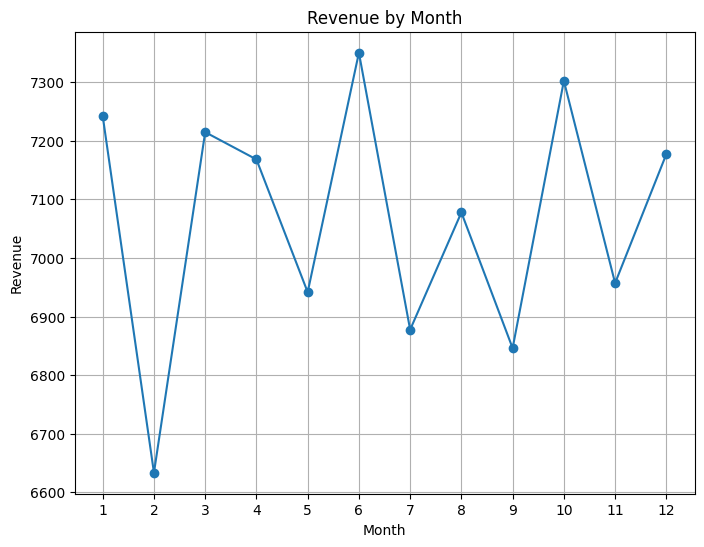

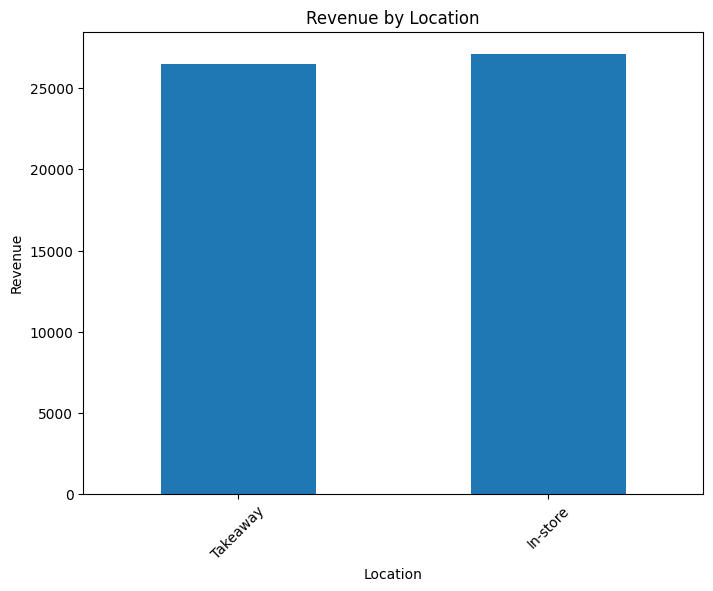

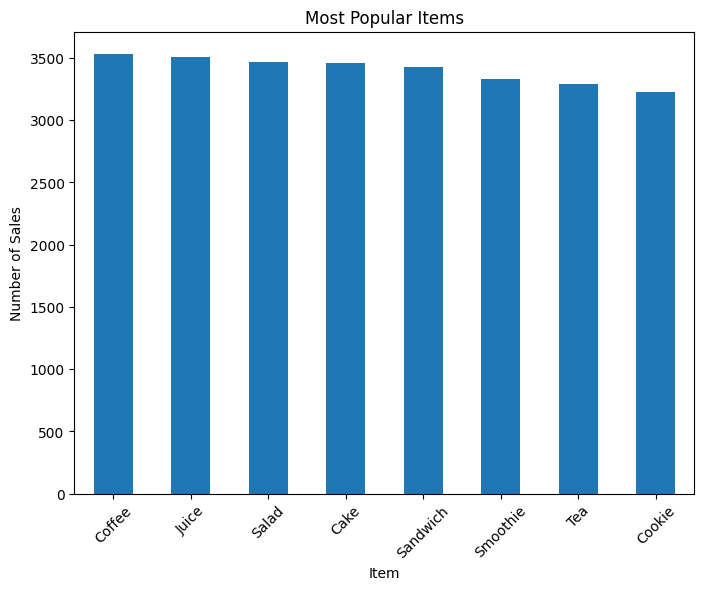

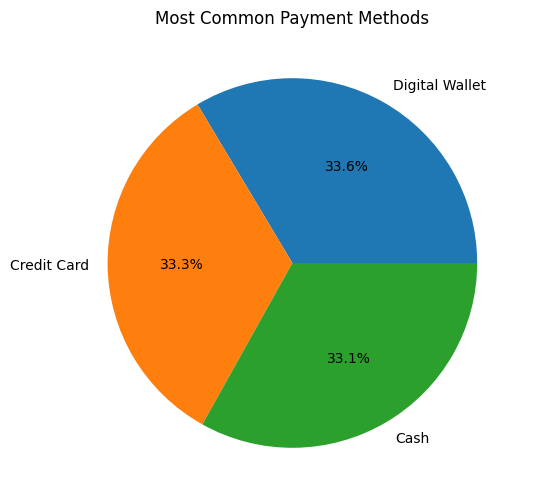

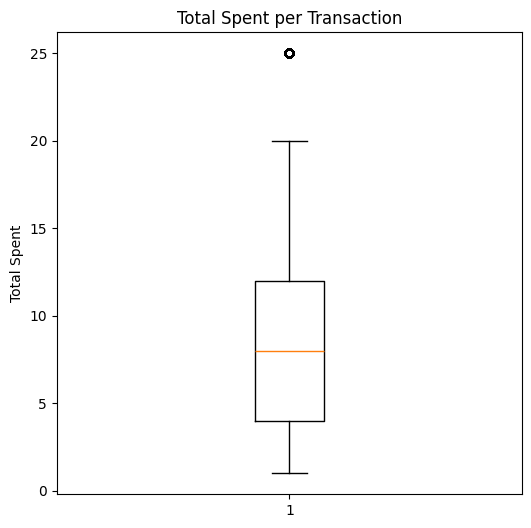

In [12]:
# Revenue by month (line)
clean_df = con.sql(f"SELECT * FROM clean_data").df()
revenue_by_month = clean_df.groupby('transaction_month')['total_spent'].sum().sort_index()

plt.figure(figsize=(8,6))
plt.plot(revenue_by_month.index, revenue_by_month.values, marker='o')
plt.title('Revenue by Month')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.grid(True)
plt.xticks(revenue_by_month.index)

plt.savefig('reports/figures/revenue_by_month.png', dpi=300)
plt.show()

# Revenue by location (bar)
revenue_by_location = clean_df.groupby('location')['total_spent'].sum().sort_values()

plt.figure(figsize=(8,6))
revenue_by_location.plot(kind='bar')
plt.title('Revenue by Location')
plt.xlabel('Location')
plt.ylabel('Revenue')
plt.xticks(rotation=45)

plt.savefig('reports/figures/revenue_by_location.png', dpi=300)
plt.show()

# Item popularity (bar)
item_popularity = clean_df.groupby('item')['quantity'].sum().sort_values(ascending=False)

plt.figure(figsize=(8,6))
item_popularity.plot(kind='bar')
plt.title('Most Popular Items')
plt.xlabel('Item')
plt.ylabel('Number of Sales')
plt.xticks(rotation=45)

plt.savefig('reports/figures/item_popularity.png', dpi=300)
plt.show()

# Common payment methods (donut)
payment_counts = clean_df['payment_method'].value_counts()

plt.figure(figsize=(6,6))
plt.pie(payment_counts, labels=payment_counts.index, autopct='%1.1f%%')
plt.title('Most Common Payment Methods')

plt.savefig('reports/figures/payment_methods.png', dpi=300)
plt.show()

# Total spent per transaction (box)
plt.figure(figsize=(6,6))
plt.boxplot(clean_df['total_spent'].dropna())
plt.title('Total Spent per Transaction')
plt.ylabel('Total Spent')

plt.savefig('reports/figures/transaction_box_plot.png', dpi=300)
plt.show()